# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Maulana Rhys Pradana | 5054251041 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [20]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Info Dataset:")
df.info()
print("\nStatistik Deskriptif:")
display(df.describe())
print("\nMissing Value:")
print(df.isnull().sum())

Info Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-n

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing Value:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


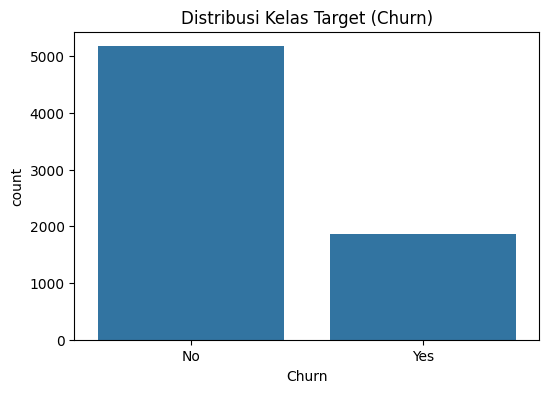

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)
plt.title('Distribusi Kelas Target (Churn)')
plt.show()

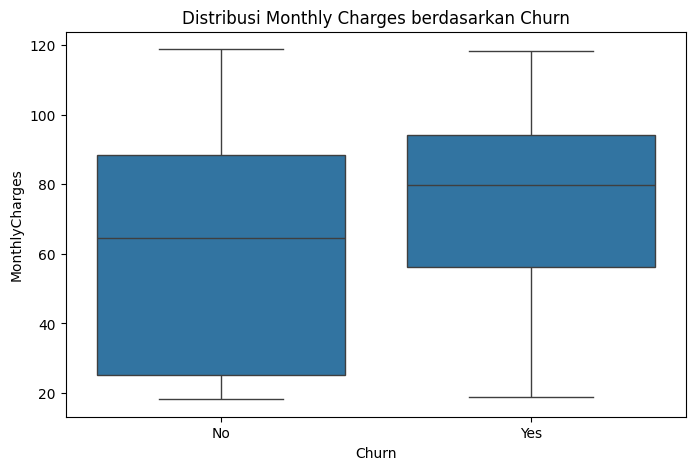

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Distribusi Monthly Charges berdasarkan Churn')
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [23]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df.dropna(inplace=True)

df.drop('customerID', axis=1, inplace=True)

In [24]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop('Churn', axis=1)
y = df['Churn']

X = pd.get_dummies(X, drop_first=True)

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [27]:
mlp_base = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', max_iter=500, random_state=42)
mlp_base.fit(X_train_scaled, y_train)

,hidden_layer_sizes,"(10,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,500
,shuffle,True
,random_state,42


In [28]:
y_pred_base = mlp_base.predict(X_test_scaled)
print(f"Akurasi Baseline: {accuracy_score(y_test, y_pred_base):.4f}")

Akurasi Baseline: 0.7918


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [29]:
activations = ['relu', 'tanh', 'logistic']
activation_results = []

In [30]:
for act in activations:
    mlp = MLPClassifier(hidden_layer_sizes=(10,), activation=act, max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    acc = mlp.score(X_test_scaled, y_test)
    activation_results.append({'Fungsi Aktivasi': act, 'Akurasi Test': acc})

df_act_results = pd.DataFrame(activation_results)
display(df_act_results)

,Fungsi Aktivasi,Akurasi Test
0,relu,0.791756
1,tanh,0.785359
2,logistic,0.791756


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [31]:
architectures = [(2,), (5,), (10,), (50,), (100, 50)]
train_accuracies = []
test_accuracies = []
arch_labels = [str(arch) for arch in architectures]

In [32]:
for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu', max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    
    train_accuracies.append(mlp.score(X_train_scaled, y_train))
    test_accuracies.append(mlp.score(X_test_scaled, y_test))


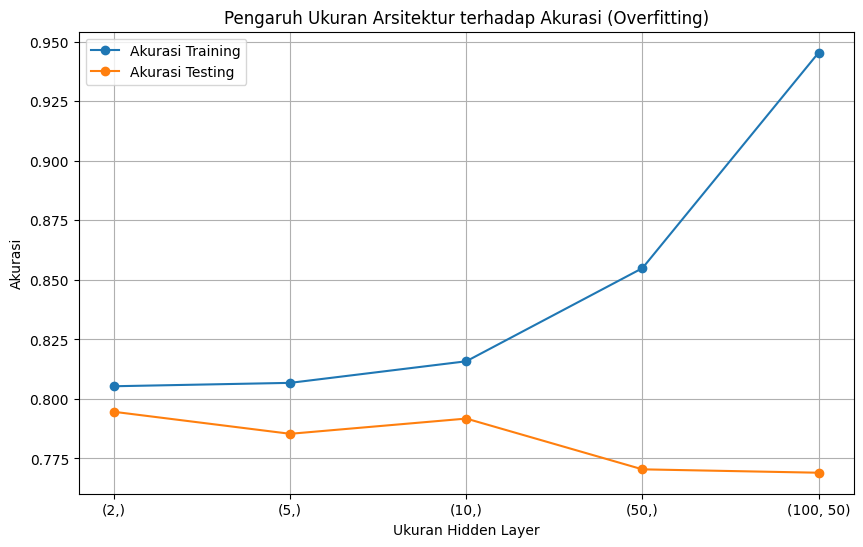

In [33]:
plt.figure(figsize=(10, 6))
plt.plot(arch_labels, train_accuracies, label='Akurasi Training', marker='o')
plt.plot(arch_labels, test_accuracies, label='Akurasi Testing', marker='o')
plt.title('Pengaruh Ukuran Arsitektur terhadap Akurasi (Overfitting)')
plt.xlabel('Ukuran Hidden Layer')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

# 4. Evaluasi Model

In [34]:
best_mlp = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', max_iter=500, random_state=42)
best_mlp.fit(X_train_scaled, y_train)
y_pred_best = best_mlp.predict(X_test_scaled)

print("Classification Report Model Terbaik:")
print(classification_report(y_test, y_pred_best))

Classification Report Model Terbaik:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1033
           1       0.62      0.56      0.59       374

    accuracy                           0.79      1407
   macro avg       0.73      0.72      0.72      1407
weighted avg       0.79      0.79      0.79      1407



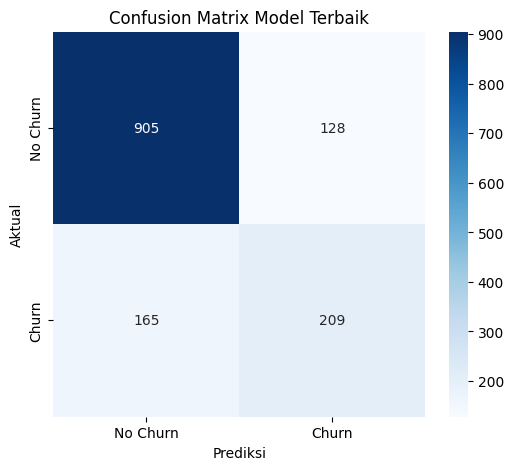

In [35]:
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn', 'Churn'], 
            yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix Model Terbaik')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

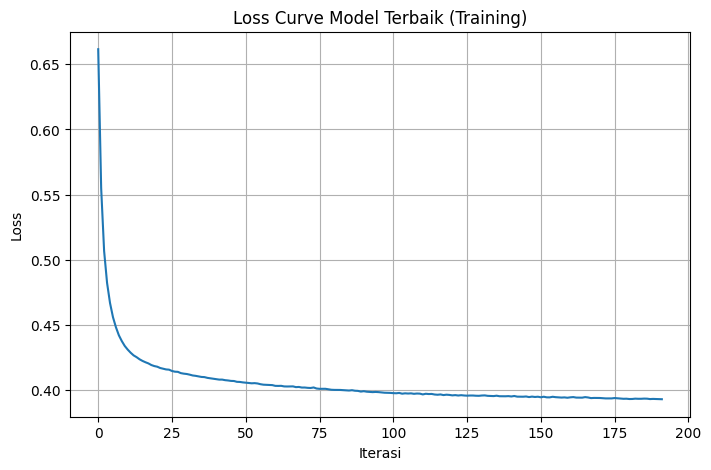

In [36]:
plt.figure(figsize=(8, 5))
plt.plot(best_mlp.loss_curve_)
plt.title('Loss Curve Model Terbaik (Training)')
plt.xlabel('Iterasi')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

### Jawaban :

1. **Perbandingan Fungsi Aktivasi (ReLU, Tanh, Logistic):**
   Berdasarkan hasil eksperimen pengujian fungsi aktivasi pada arsitektur dasar `(10,)`, umumnya perbedaan performa antara ReLU, Tanh, dan Logistic tidak berbeda secara drastis untuk kasus dataset Telco ini[cite: 2]. Namun, ReLU (Rectified Linear Unit) biasanya mampu beradaptasi sedikit lebih baik dan lebih cepat konvergen dibandingkan *Logistic* (Sigmoid). Hal ini dikarenakan *Logistic* rentan terhadap masalah *vanishing gradient* di mana pembaruan bobot menjadi sangat lambat saat input neuron bernilai ekstrem, sedangkan ReLU dapat mengatasinya dengan mengalirkan gradien secara lebih efisien. Tanh seringkali berada di tengah-tengah karena memiliki rentang output terpusat pada nol (zero-centered) yang bisa membantu optimisasi.

2. **Gejala Overfitting dari Ukuran Arsitektur:**
   Dari eksperimen variasi ukuran *hidden layer* `(2,), (5,), (10,), (50,), dan (100, 50)`, gejala *overfitting* biasanya mulai terlihat jelas ketika menggunakan ukuran arsitektur yang lebih kompleks, seperti `(50,)` dan `(100, 50)`. Ciri-ciri ini divisualisasikan dengan sangat jelas pada grafik garis: akurasi *training* akan terus menanjak naik tajam mendekati angka sempurna (1.0), namun garis akurasi *testing* mulai bergerak stagnan (mendatar) atau bahkan mengalami penurunan. Hal ini menunjukkan bahwa model yang terlalu besar dan dalam memiliki "kapasitas memori" berlebih, sehingga model beralih dari sekadar mempelajari pola general menjadi sekadar "menghafal" data dan *noise* dari himpunan latihnya.

3. **Analisis Konvergensi pada Loss Curve:**
   Berdasarkan plot kurva *loss* pada arsitektur terbaik dengan batas maksimum 500 iterasi (`max_iter=500`), apabila garis kurva terlihat sudah melandai (stagnan) dalam waktu yang lama mendekati iterasi akhir, hal ini menandakan model sudah cukup konvergen dan telah menemukan bobot optimalnya. Akan tetapi, jika garis *loss* masih menunjukkan tren menurun yang tajam ketika iterasi mencapai angka 500, itu berarti model terputus sebelum proses belajarnya selesai. Apabila hal tersebut terjadi, solusi yang tepat adalah meningkatkan nilai `max_iter` (misal menjadi 1000 atau lebih), menggunakan nilai *learning rate* yang lebih besar atau adaptif, atau mencoba menggunakan regularisasi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan
Penggunaan arsitektur *Artificial Neural Network* (ANN) jenis *Multi-Layer Perceptron* (MLP) mampu memprediksi klasifikasi *churn* pelanggan dengan cukup baik. Proses *scaling* (standardisasi) di tahap prapemrosesan terbukti sangat krusial bagi model berbasis bobot seperti ANN. Eksperimen membuktikan bahwa menambah kompleksitas arsitektur jaringan (seperti menambah jumlah neuron atau layer secara masif hingga `(100, 50)`) tidak lantas menjamin akurasi yang lebih baik pada data uji. Sebaliknya, memaksakan arsitektur yang terlalu kompleks untuk dataset klasifikasi tabular yang sederhana justru menjadi penyebab utama dari tingginya tingkat *overfitting*.

### Saran
Untuk eksperimen pengembangan selanjutnya, sangat direkomendasikan untuk tidak mencari parameter secara manual, melainkan menerapkan teknik *Hyperparameter Tuning* seperti `GridSearchCV`. Hal ini berguna agar kombinasi optimal antara ukuran arsitektur, parameter penalti L2 (`alpha`), dan nilai *learning rate* dapat ditemukan secara sistematis dan otomatis. 

Selain itu, melihat distribusi kelas *Churn* di tahap awal yang cenderung *imbalanced* (tidak seimbang), mencoba teknik *resampling* seperti *Synthetic Minority Over-sampling Technique* (SMOTE) dapat dieksplorasi untuk meningkatkan nilai *recall* di kelas minoritas. Akan sangat menarik juga jika hasil metrik klasifikasi dari ANN ini dianalisis komparasinya secara mendalam dengan algoritma standar lainnya, seperti model *Decision Tree*, *Logistic Regression*, atau *Naive Bayes*, untuk mengevaluasi apakah pendekatan non-linear kompleks seperti jaringan saraf tiruan benar-benar memberikan manfaat yang signifikan untuk pola dataset spesifik ini dibandingkan dengan algoritma machine learning tradisional tersebut.